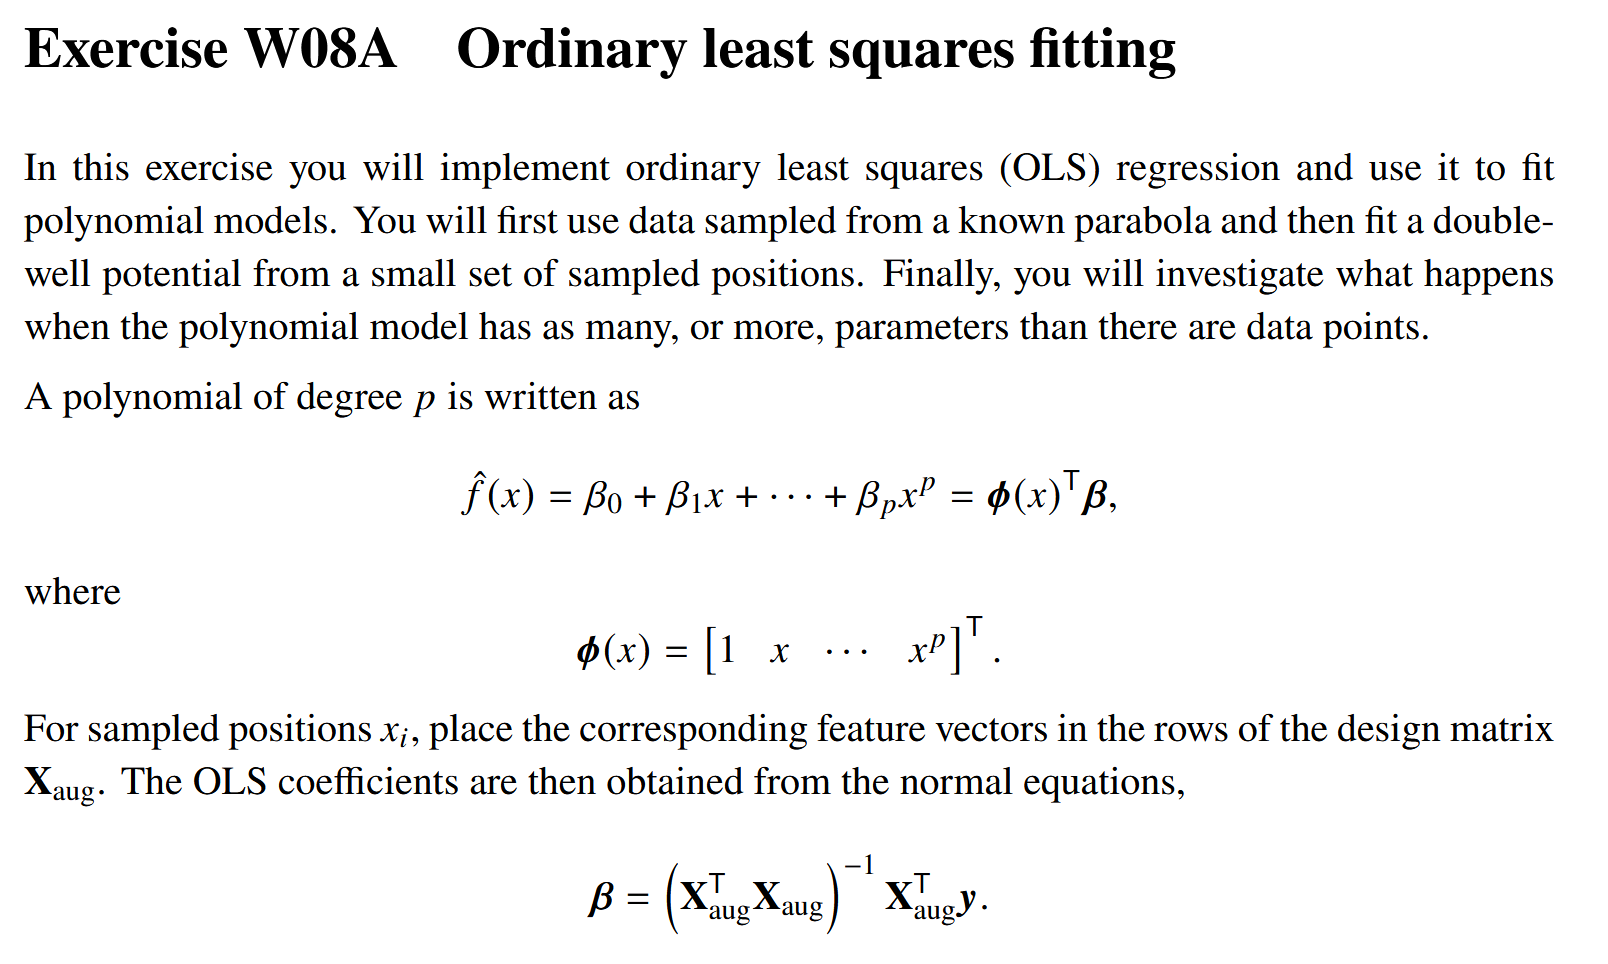
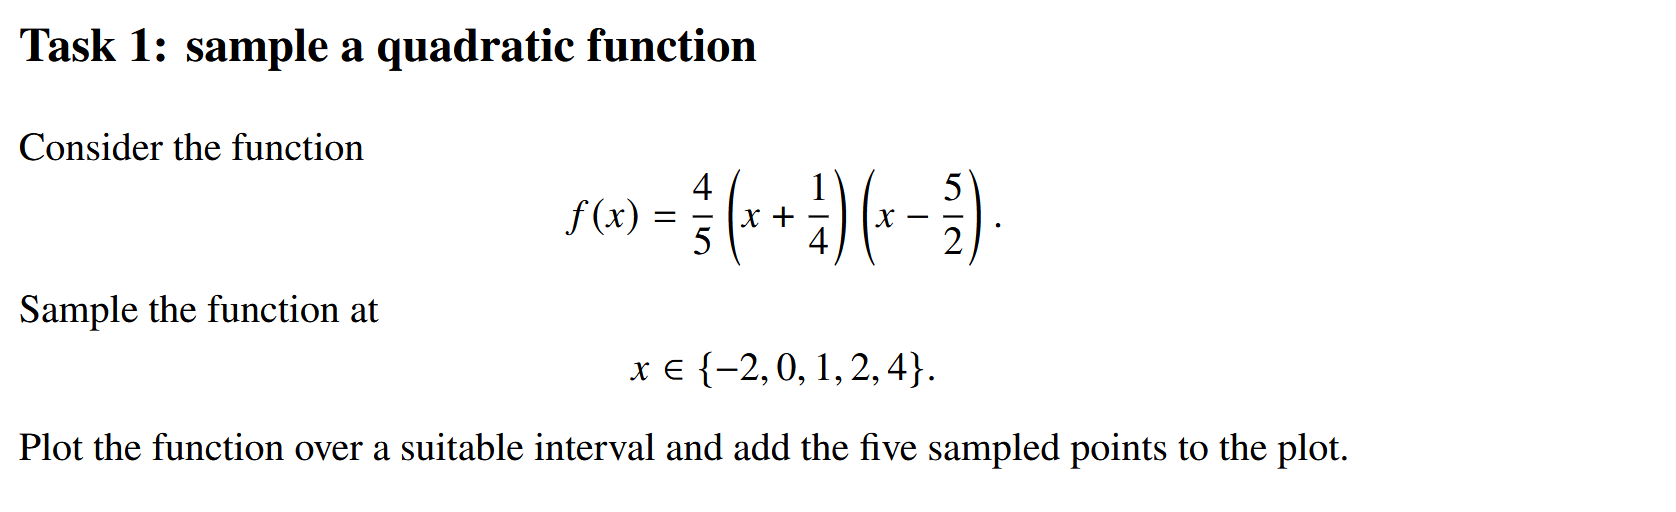

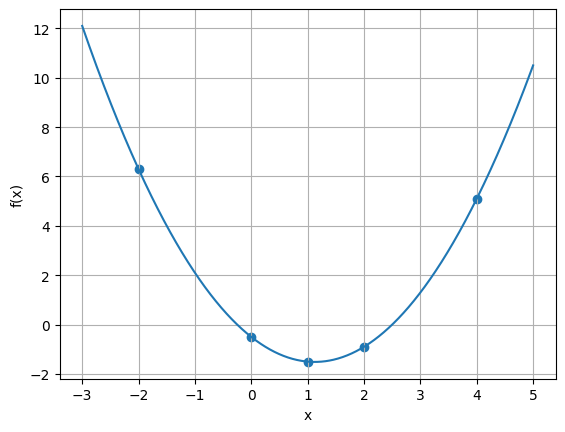

In [175]:
import numpy as np
import matplotlib.pyplot as plt 

def f(x):
    return 0.8 * (x + 0.25) * (x - 2.5)

lin_x = np.linspace(-3, 5, 1000)
x = np.array([-2, 0, 1, 2, 4])

plt.scatter(x, f(x))
plt.plot(lin_x, f(lin_x))
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

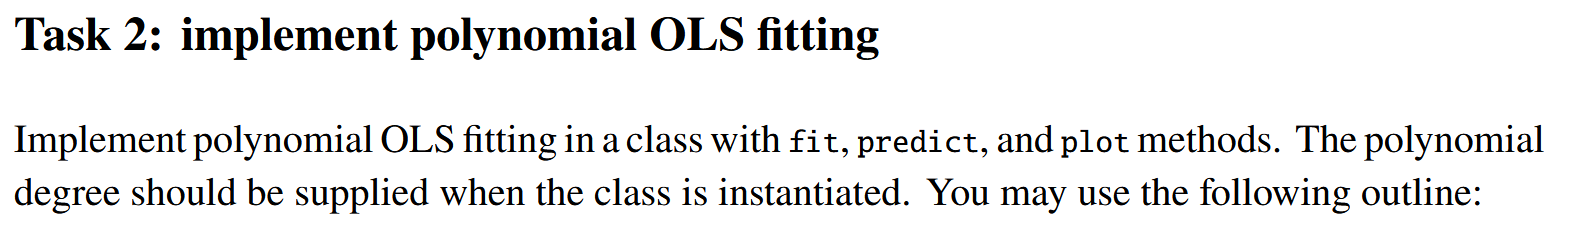
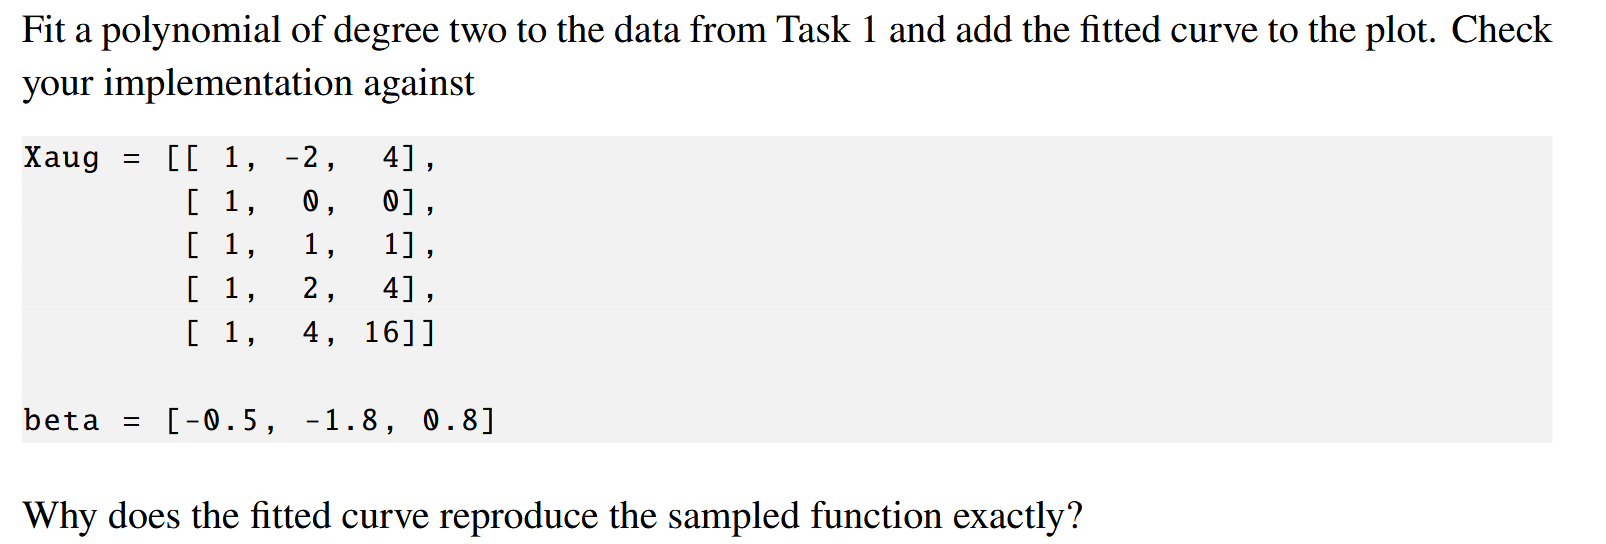

In [176]:
class OLFitPoly:
    def __init__(self, Ndegree):
        self.Ndegree = Ndegree
        self.beta = None

    def fit(self, X, y):
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])
        Xs = np.linalg.inv(X_aug.T @ X_aug) @ X_aug.T
        self.beta = Xs @ y
        return self.beta, X_aug

    def predict(self, X):
        if type(self.beta) == type(None):
            raise ValueError('No β, run .fit() first')
        
        X_aug = np.array([[x**p for p in range(self.Ndegree + 1)] for x in X])

        return X_aug @ self.beta

    def plot(self, ax, X): 
        y = self.predict(X)
        ax.scatter(X, y)


OL = OLFitPoly(2)
beta, X_aug = OL.fit(x, f(x))
print(f'β = ', beta)
print(f'X_aug = \n', X_aug)


β =  [-0.5 -1.8  0.8]
X_aug = 
 [[ 1 -2  4]
 [ 1  0  0]
 [ 1  1  1]
 [ 1  2  4]
 [ 1  4 16]]


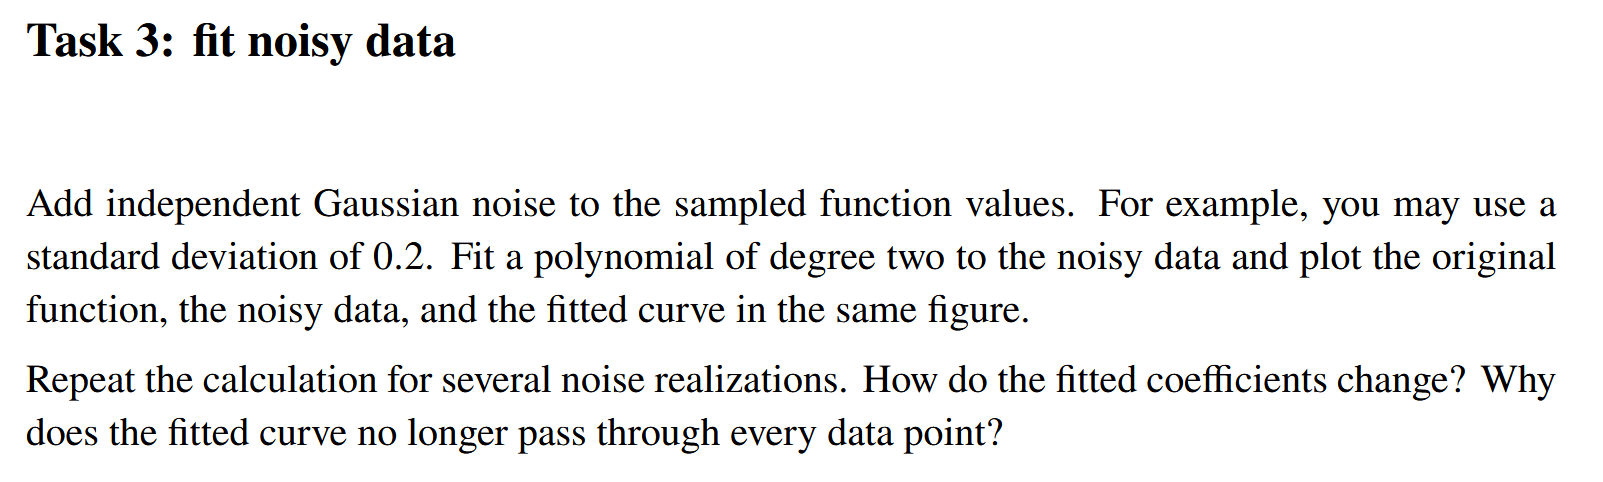

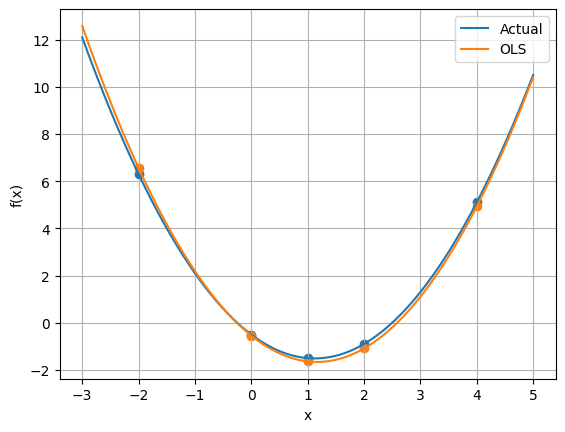

In [177]:
y_n = f(x) + np.random.normal(scale=0.4, size=x.shape)


fig, ax = plt.subplots(1, 1)

OL.fit(x, y_n)

ax.scatter(x, f(x))
OL.plot(ax, x)
ax.plot(lin_x, f(lin_x), label='Actual')
ax.plot(lin_x, OL.predict(lin_x), label='OLS')
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.legend()
ax.grid()

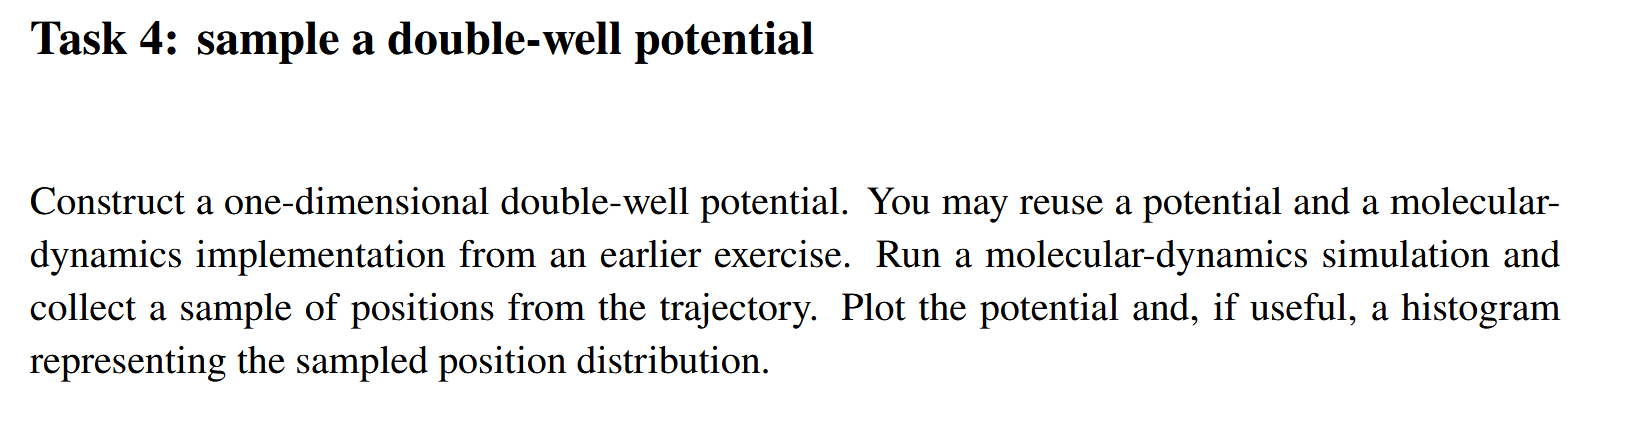
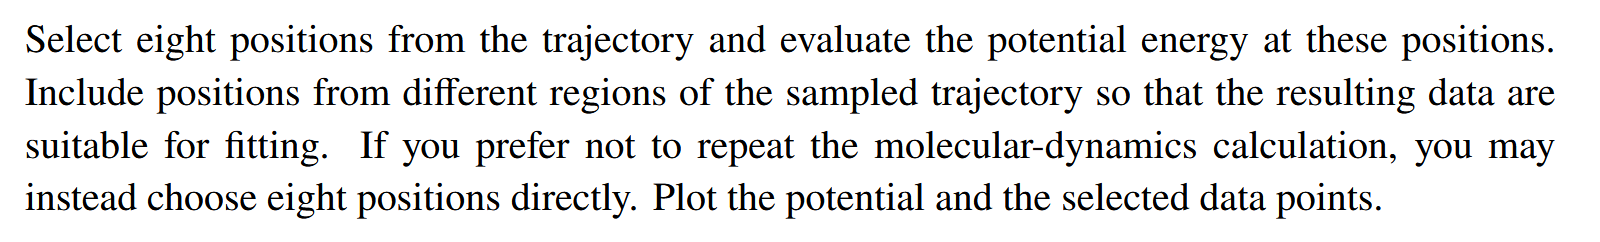

Text(0, 0.5, 'V(x)')

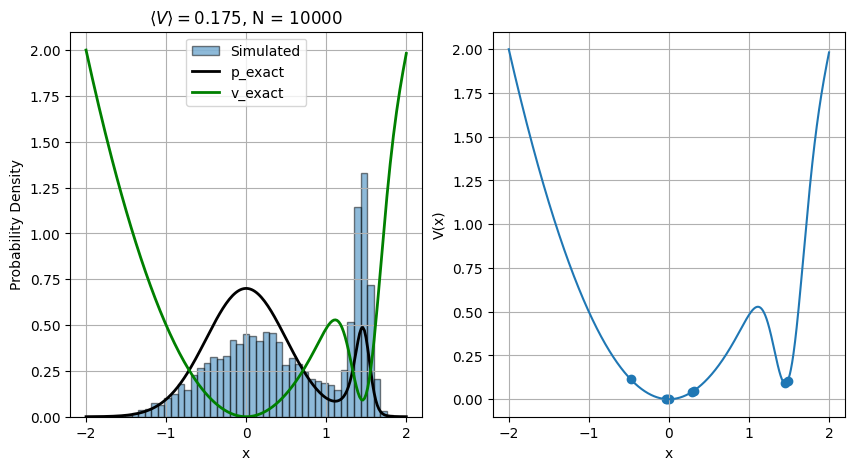

In [178]:
from Metropolis import *

class DoubleWell():
    def __init__(self, k=1, x0=0, a1=-1, x1=1.5, λ=0.25):
        self.k = k
        self.x0 = x0
        self.a1 = a1
        self.x1 = x1
        self.λ = λ

    def V(self, x):
        return 0.5 * self.k * (x - self.x0)**2 + self.a1 * np.exp(-(x-self.x1)**2/(self.λ**2))

    def F(self, x):
        return -self.k * (x - self.x0) + (2 * (x - self.x1) / self.λ**2) * self.a1 * np.exp(-(x - self.x1)**2 / self.λ**2)

potential = DoubleWell()
met = Metropolis(calc=potential, initial_state=0, kT=0.25)
pos, energy = met.run()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
met.plot(ax1, -2, 2)

points = np.random.choice(pos, 8)
x_lin = np.linspace(-2, 2, 1000)
ax2.plot(x_lin, potential.V(x_lin))
ax2.scatter(points, potential.V(points))
ax2.grid()
ax2.set_xlabel('x')
ax2.set_ylabel('V(x)')

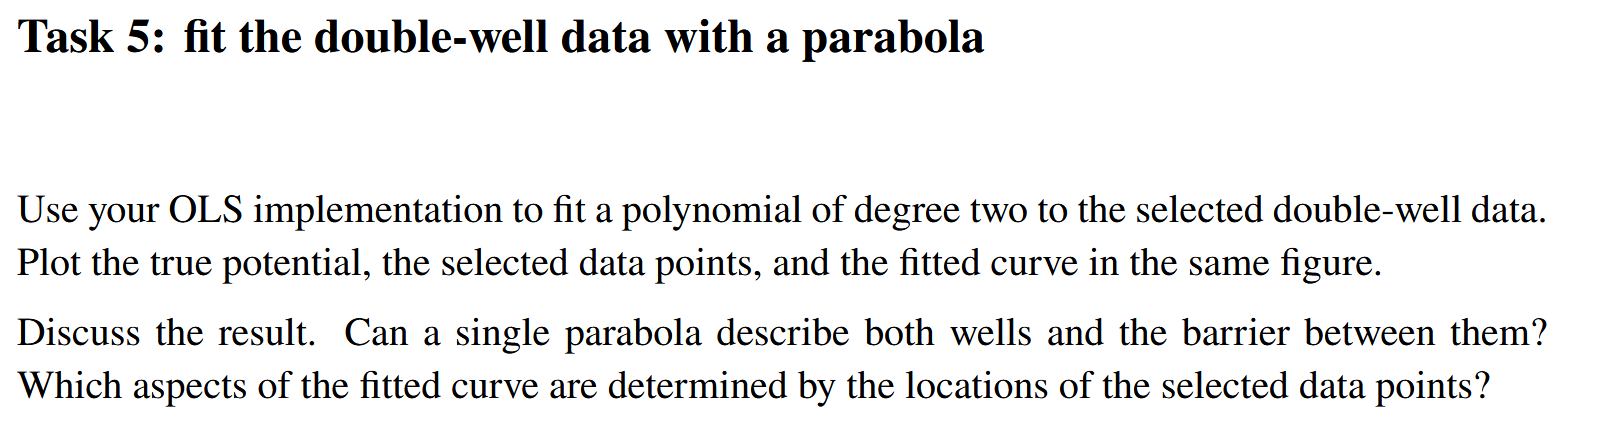

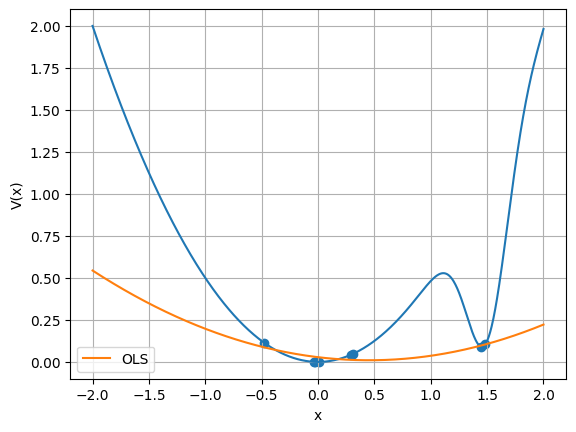

In [179]:
ols = OLFitPoly(2)
ols.fit(points, potential.V(points))

fig, ax = plt.subplots(1, 1)
ax.plot(x_lin, potential.V(x_lin))
ax.scatter(points, potential.V(points))

ax.plot(x_lin, ols.predict(x_lin), label='OLS')
ax.grid()
ax.set_xlabel('x')
ax.set_ylabel('V(x)')
ax.legend()

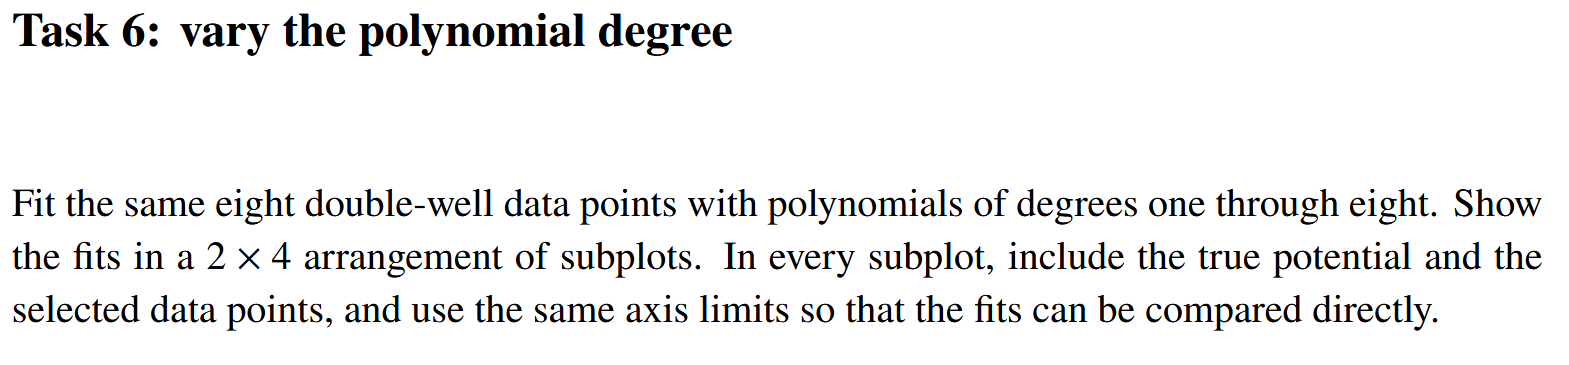
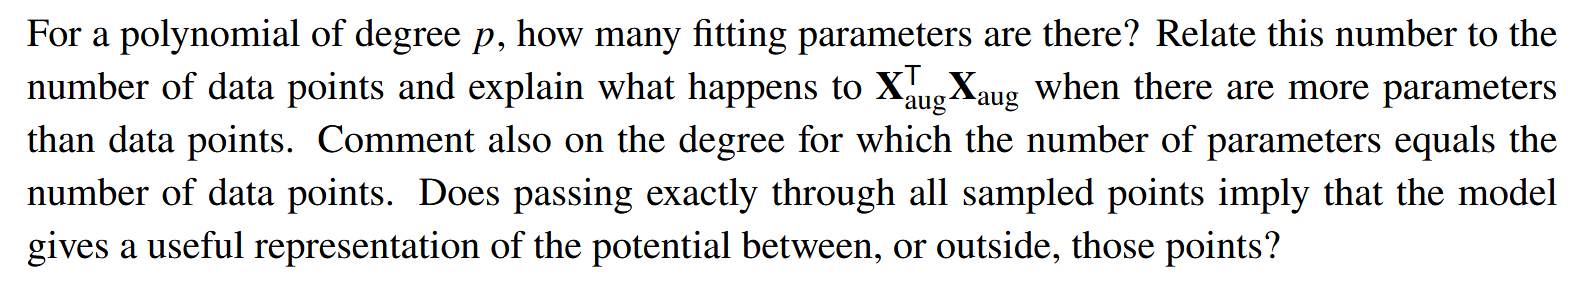

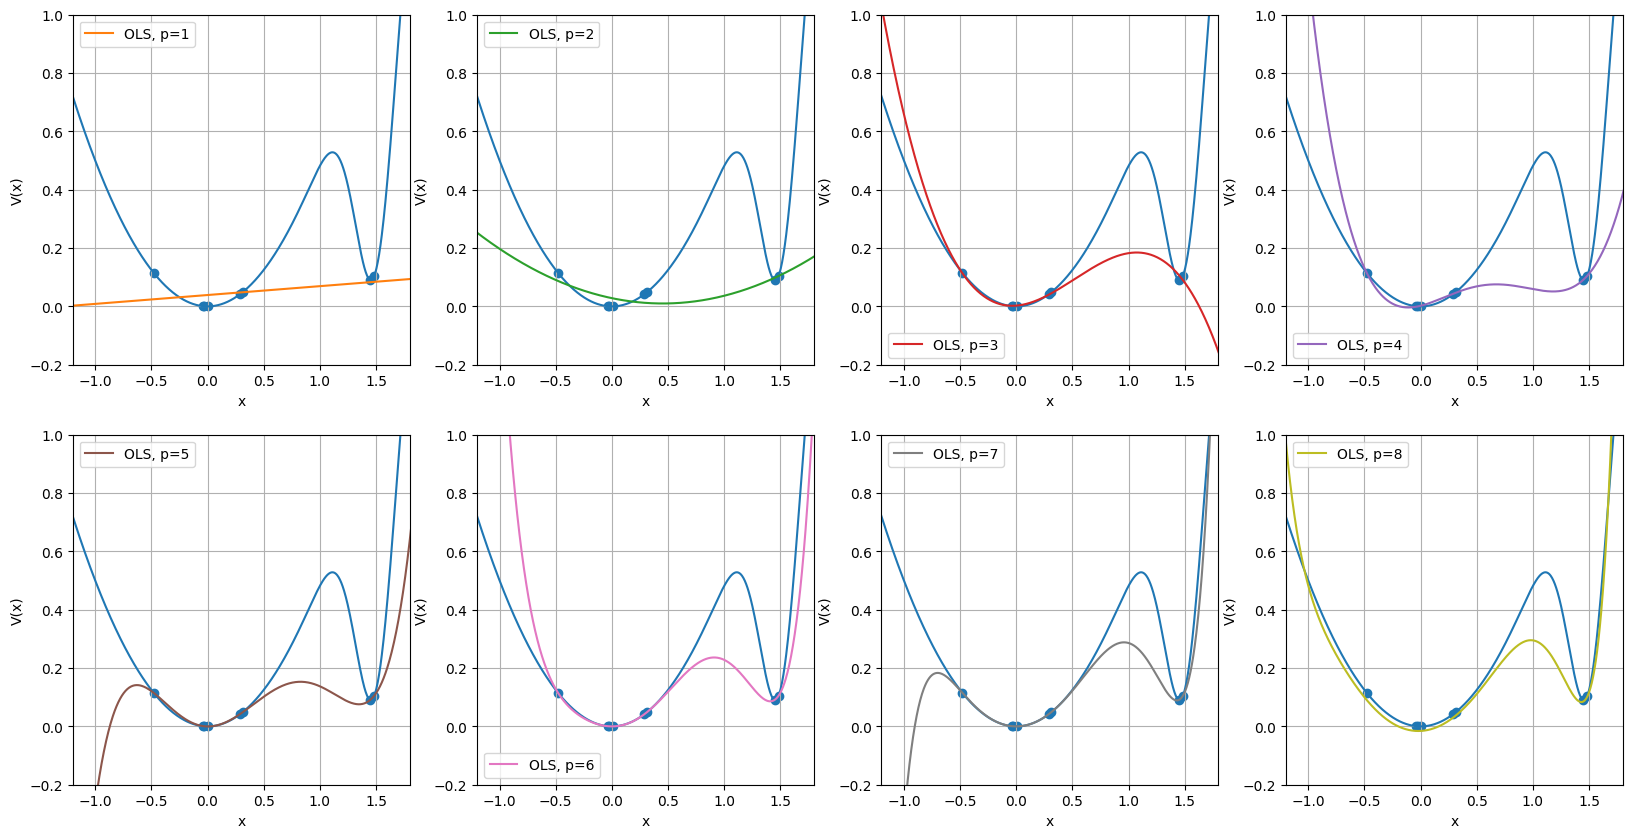

In [183]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    ols = OLFitPoly(i+1)
    ols.fit(points, potential.V(points))

    ax.plot(x_lin, potential.V(x_lin))
    ax.scatter(points, potential.V(points))

    ax.plot(x_lin, ols.predict(x_lin), label=f'OLS, p={i+1}', color=f'C{i+1}')
    ax.grid()
    ax.set_xlabel('x')
    ax.set_ylabel('V(x)')

    ax.set_xlim(-1.2, 1.8)
    ax.set_ylim(-0.2, 1.0)
    ax.legend()

fig.savefig('w08_p8')

more degrees then points make the matrix singular, and gives and endless amount off solutions. Cant solve inverse of singular matrix

In [182]:
print(points)

[-0.02743459  0.00559573  1.48419862  1.4480335   0.28985161 -0.47948095
  0.31194129 -0.0374767 ]
